In [1]:
!pip install polars scikit-learn mlflow numpy matplotlib seaborn

In [2]:
import polars as pl
from sklearn.model_selection import cross_validate, train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, accuracy_score, make_scorer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
import mlflow
import mlflow.sklearn
import numpy as np
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

In [3]:
df_reviews_repro = pl.read_csv(
    '../data/RePro.csv',
    schema_overrides={"product_id": pl.String}
)
df_reviews_repro


submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,review_text,overall_rating,recommend_to_a_friend,reviewer_birth_year,reviewer_gender,reviewer_state,topics,polarity,ENTREGA,OUTROS,PRODUTO,CONDICOESDERECEBIMENTO,INADEQUADA,ANUNCIO
str,str,str,str,str,str,str,str,str,i64,str,i64,str,str,str,str,i64,i64,i64,i64,i64,i64
"""2018-05-14 13:57:59""","""a4380c38e7e73687066bf66329454b…","""34398895""","""Kit Com 10 Cuecas Boxer de Cot…",null,"""Moda""","""Masculino""","""""O PRODUTO QUE NÃO ESTÁ AGRADA…","""ESSE PRODUTO PODE ATÉ SER BOM,…",3,"""Yes""",1959,"""M""","""SP""","""['ENTREGA', 'OUTROS']""","""['NEGATIVO', 'POSITIVO']""",1,1,0,0,0,0
"""2018-01-18 12:02:42""","""fbf1d015682ddd45f97cedbc935fd4…","""132444050""","""Smartphone Motorola Moto G 5S …",null,"""Celulares e Smartphones""","""Smartphone""","""""compra sem susto""""","""Aparelho muito bom, confiável …",4,"""No""",1955,"""M""","""ES""","""['PRODUTO']""","""['POSITIVO']""",0,0,1,0,0,0
"""2018-04-18 12:06:14""","""6042f06b0d63fd46499b2f6eed116d…","""132710805""","""Impressora Hp Sprocket 100 Jat…",null,"""Câmeras e Filmadoras""","""Impressora e Papel Fotográfico""","""*""","""As cores da impressão não são …",3,"""No""",1961,"""F""","""MG""","""['PRODUTO']""","""['NEGATIVO']""",0,0,1,0,0,0
"""2018-01-23 08:11:11""","""4871f745136a74808a49970db18d20…","""119882282""","""Livro - It: A Coisa""",null,"""Livros""","""Literatura Estrangeira""","""***""","""A história é muito boa, porém …",3,"""Yes""",1971,"""F""","""MG""","""['PRODUTO']""","""['NEGATIVO', 'POSITIVO']""",0,0,1,0,0,0
"""2018-02-17 11:19:38""","""6141e659c620ab597a5cda1b9150e1…","""23218825""","""Termometro Laser Digital Infra…",null,"""Bebês""","""Higiene e Saúde""","""****""","""Entrega rápida, produto muito …",4,"""Yes""",1981,"""F""","""SP""","""['ENTREGA', 'PRODUTO']""","""['POSITIVO']""",1,0,1,0,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""2018-03-28 20:28:48""","""872e883107226e47ac884fdaa8f998…","""129729177""","""Jogo de Jantar 42 Peças de Por…","""rojemac""","""Utilidades Domésticas""","""Pratos e Talheres""","""ótimo produto.""","""amei o produto. chegou no praz…",5,"""Yes""",1992,"""F""","""BA""","""['CONDICOESDERECEBIMENTO', 'EN…","""['POSITIVO']""",1,0,1,1,0,0
"""2018-04-26 14:52:35""","""f54ed3e93b36898283b93989eca374…","""24501843""","""Sistema De Terapia Homeopet Pa…",null,"""Pet Shop""","""Gatos""","""ótimo""","""Ótima embalagem. Produto entre…",5,"""Yes""",1976,"""F""","""RJ""","""['CONDICOESDERECEBIMENTO', 'EN…","""['POSITIVO']""",1,0,1,1,0,0
"""2018-04-20 06:16:33""","""e538b1e5b72a77ca5edb2e80631f2b…","""129164073""","""Cabide Aveludado para Cintos -…","""orb""","""Utilidades Domésticas""","""Cabide, Cestos e Varal de Roup…","""ótimo""","""ótimo produto, super recomendo…",5,"""Yes""",1987,"""F""","""RJ""","""['ENTREGA', 'PRODUTO']""","""['POSITIVO']""",1,0,1,0,0,0


In [4]:
df_reviews_repro.describe()

statistic,submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,review_text,overall_rating,recommend_to_a_friend,reviewer_birth_year,reviewer_gender,reviewer_state,topics,polarity,ENTREGA,OUTROS,PRODUTO,CONDICOESDERECEBIMENTO,INADEQUADA,ANUNCIO
str,str,str,str,str,str,str,str,str,str,f64,str,f64,str,str,str,str,f64,f64,f64,f64,f64,f64
"""count""","""10003""","""10003""","""10003""","""9997""","""2967""","""10003""","""9708""","""10003""","""10003""",10003.0,"""10001""",9565.0,"""9703""","""9715""","""10003""","""10003""",10003.0,10003.0,10003.0,10003.0,10003.0,10003.0
"""null_count""","""0""","""0""","""0""","""6""","""7036""","""0""","""295""","""0""","""0""",0.0,"""2""",438.0,"""300""","""288""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",null,null,null,null,null,null,null,null,null,3.0004,null,1976.943962,null,null,null,null,0.310907,0.235529,0.781965,0.171049,0.041088,0.087374
"""std""",null,null,null,null,null,null,null,null,null,1.414143,null,30.506792,null,null,null,null,0.462888,0.42435,0.412932,0.37657,0.198503,0.282396
"""min""","""2018-01-01 00:26:02""","""0014cadc935c236000a14673d7e860…","""10029771""","""""Celular Lg B-220 Dual Sim 1.4…","""2k games""","""Agro, Indústria e Comércio""","""Acessórios Consoles Clássicos""","""""O PRODUTO QUE NÃO ESTÁ AGRADA…","""!!!!!!!!!!!!!!!!Primeira Bicic…",1.0,"""No""",66.0,"""F""","""AC""","""['ANUNCIO', 'CONDICOESDERECEBI…","""['NEGATIVO', 'POSITIVO']""",0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",null,null,null,null,null,null,null,null,null,2.0,null,1969.0,null,null,null,null,0.0,0.0,1.0,0.0,0.0,0.0
"""50%""",null,null,null,null,null,null,null,null,null,3.0,null,1980.0,null,null,null,null,0.0,0.0,1.0,0.0,0.0,0.0
"""75%""",null,null,null,null,null,null,null,null,null,4.0,null,1987.0,null,null,null,null,1.0,0.0,1.0,0.0,0.0,0.0
"""max""","""2018-05-31 22:36:43""","""ffff18add78ee23048add81e7c9c1a…","""9990301""","""Óleo de Groselha negra 30 cáps…","""zte""","""Áudio""","""Ótica""","""ùnico Tonner que deu certo na …","""ótimo produto. Está funcionan…",5.0,"""Yes""",2018.0,"""M""","""TO""","""['PRODUTO']""","""['POSITIVO']""",1.0,1.0,1.0,1.0,1.0,1.0


In [5]:
df_reviews_repro = (
    df_reviews_repro
    .select(['review_text', 'overall_rating']) 
    .drop_nulls(subset=['review_text', 'overall_rating'])                                         
    .with_columns(                                                                                
        pl.when(pl.col('overall_rating') <= 2).then(0)
        .when(pl.col('overall_rating') == 3).then(1)
        .otherwise(2)
        .alias('label')
    )
)

In [6]:
print(f'Total de instâncias:{df_reviews_repro.shape[0]}')

print(f'\nDistribuição de classes:\n{df_reviews_repro['label'].value_counts(normalize=True) * 100}')

Total de instâncias:10003

Distribuição de classes:
shape: (3, 2)
┌───────┬────────────┐
│ label ┆ proportion │
│ ---   ┆ ---        │
│ f64   ┆ f64        │
╞═══════╪════════════╡
│ 0.0   ┆ 39.978007  │
│ 100.0 ┆ 20.03399   │
│ 200.0 ┆ 39.988004  │
└───────┴────────────┘


In [7]:
X = df_reviews_repro['review_text']
y = df_reviews_repro['label']

In [8]:
vec = TfidfVectorizer()
vec.fit(X)
vocab_size = len(vec.vocabulary_)
print(f"Total de palavras distintas no corpus: {vocab_size}")

Total de palavras distintas no corpus: 14214


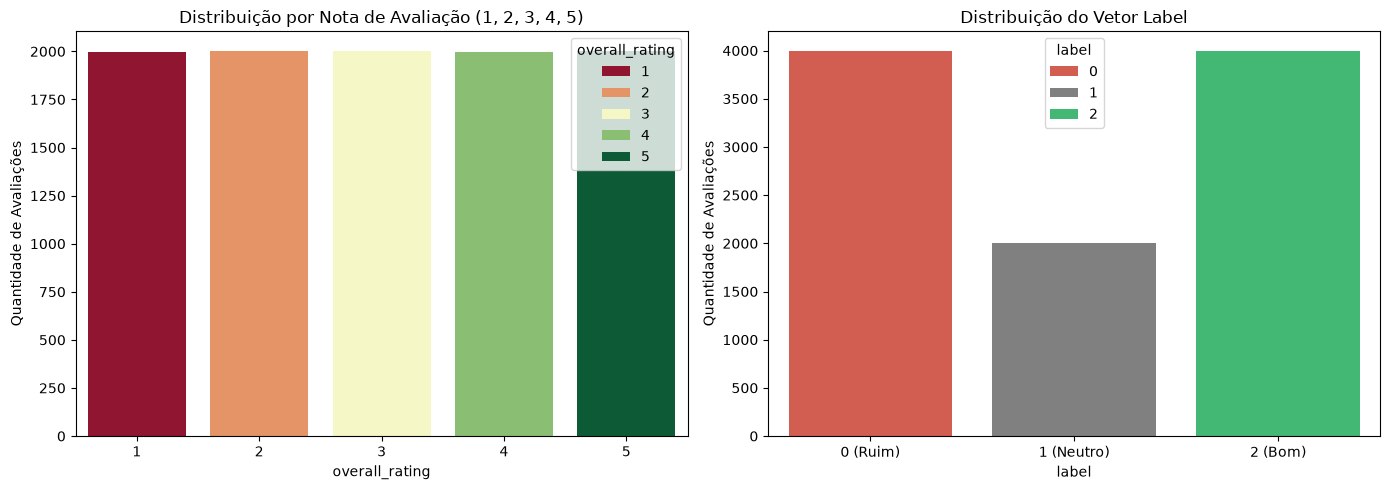

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df_reviews_repro,
    x='overall_rating',
    hue='overall_rating',
    palette='RdYlGn',
    ax=axes[0],
)
axes[0].set_title("Distribuição por Nota de Avaliação (1, 2, 3, 4, 5)")
axes[0].set_ylabel("Quantidade de Avaliações")

sns.countplot(
    data=df_reviews_repro,
    x='label',
    hue='label',
    palette=["#e74c3c", "#808080", "#2ecc71"],
    ax=axes[1],
)
axes[1].set_title("Distribuição do Vetor Label")
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(['0 (Ruim)', '1 (Neutro)', '2 (Bom)'])
axes[1].set_ylabel("Quantidade de Avaliações")

plt.tight_layout()
plt.show()


In [10]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive_Bayes": MultinomialNB(),
    "SVM_OvO": SVC(kernel='linear', decision_function_shape='ovo', class_weight='balanced', random_state=42),
    "Decision_Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42)
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Baseline_RePro_TFIDF")

for model_name, classifier in models.items():

    with mlflow.start_run(run_name=f"{model_name}_Olist"):
        
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

        mlflow.log_param("dataset", "RePro")
        mlflow.log_param("representation", "TF-IDF")
        mlflow.log_param("classifier", model_name)
        mlflow.log_param("max_features", "None")

        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('clf', classifier)
        ])

        scoring_metrics = {
            'accuracy': 'accuracy',
            'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
            'recall_macro': make_scorer(recall_score, average='macro', zero_division=0),
            'f1_macro': make_scorer(f1_score, average='macro', zero_division=0)
        }

        cv_results = cross_validate(pipeline, X_train, y_train, cv=skf, scoring=scoring_metrics, n_jobs=-1)
        
        mlflow.log_metric("cv_accuracy_mean", np.mean(cv_results['test_accuracy']))
        mlflow.log_metric("cv_precision_mean", np.mean(cv_results['test_precision_macro']))
        mlflow.log_metric("cv_recall_mean", np.mean(cv_results['test_recall_macro']))
        mlflow.log_metric("cv_f1_macro_mean", np.mean(cv_results['test_f1_macro']))
        
        mlflow.log_metric("cv_f1_macro_std", np.std(cv_results['test_f1_macro']))
        mlflow.log_metric("cv_fit_time_mean", np.mean(cv_results['fit_time']))

        pipeline.fit(X_train, y_train)
        
        vocab_size_pipeline = len(pipeline.named_steps['tfidf'].vocabulary_)
        mlflow.log_metric("actual_num_features", vocab_size_pipeline)

        y_pred = pipeline.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='macro')

        mlflow.log_metric("test_accuracy", acc)
        mlflow.log_metric("test_precision", prec)
        mlflow.log_metric("test_recall", rec)
        mlflow.log_metric("test_f1_score", f1)

        mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="model",
            serialization_format="skops",
            skops_trusted_types=["scipy.sparse._csr.csr_matrix"]
        )

2026/09/22 21:06:58 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/22 21:06:58 INFO mlflow.store.db.utils: Updating database tables
2026/09/22 21:06:58 INFO mlflow.tracking.fluent: Experiment with name 'Baseline_RePro_TFIDF' does not exist. Creating a new experiment.
